# Milestone 2 - Positional bias and Markov chains

The full Milestone 2 analysis on the CISI corpus (Parpola numbering) is the executed notebook `src/m2_markov/m2_markov.ipynb`. This notebook gathers its outputs and the integration work:
1. the replication on the larger Wells corpus;
2. the external check against Mahadevan (1977);
3. the embedding comparison (word2vec / LLM2Vec / M3 encoder).

*Regenerate:* `python src/m2_markov/replicate_wells.py`, `python src/m2_markov/mahadevan_table1.py`, `python src/m2_markov/llm2vec.py --table`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in ("src", "src/m3_masking", "src/m4_guardrails", "src/m2_markov", "src/m1_vision"):
    sys.path.insert(0, str(ROOT / p))
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

## 1. Headline results of the M2 notebook (CISI)

In [2]:
m2 = json.load(open(ROOT / "src/m2_markov/outputs/results_summary.json"))
print(json.dumps({k: m2[k] for k in ("step2_positions", "step4_smoothing", "step5_direction")}, indent=1)[:2500])

{
 "step2_positions": {
  "distinct_beginners": 86,
  "distinct_enders": 30,
  "top_beginner": "P385",
  "top_beginner_share_pct": 17.5,
  "top_ender": "P324",
  "top_ender_share_pct": 45.3,
  "entropy_begin_bits": 5.63,
  "entropy_end_bits": 3.22,
  "flip_test_jsd": 0.891,
  "flip_test_null_max": 0.418,
  "flip_test_p": "< 0.0001"
 },
 "step4_smoothing": {
  "MLE (no smoothing)": {
   "zero_prob_events": 516,
   "perplexity": "infinite (fails)"
  },
  "Add-one (Laplace)": {
   "zero_prob_events": 0,
   "perplexity": 77.3
  },
  "Witten-Bell": {
   "zero_prob_events": 0,
   "perplexity": 40.8
  }
 },
 "step5_direction": {
  "forward_vs_backward_training_bits": [
   2.5861,
   2.5861
  ],
  "forward_vs_backward_heldout_perplexity": [
   40.43,
   40.39
  ],
  "entropy_pos1_from_start": 5.31,
  "entropy_pos1_from_end": 2.94,
  "entropy_pos2_from_start": 4.8,
  "pos1_gap_p": "< 0.0001",
  "roles": {
   "OPENER": [
    "P385",
    "P378",
    "P256"
   ],
   "ENDER": [
    "P324",
    "P08

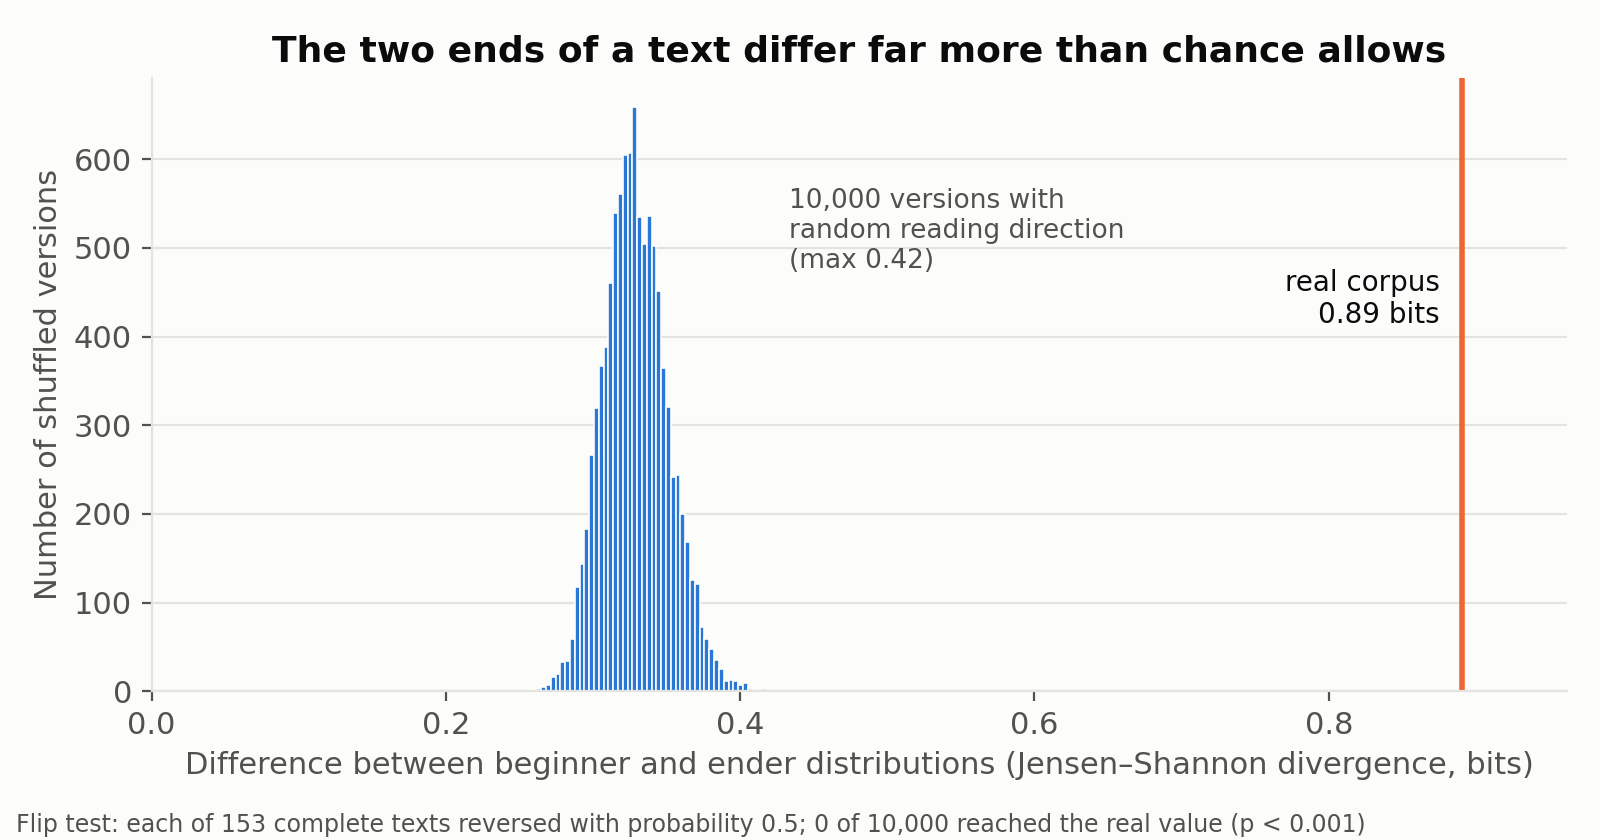

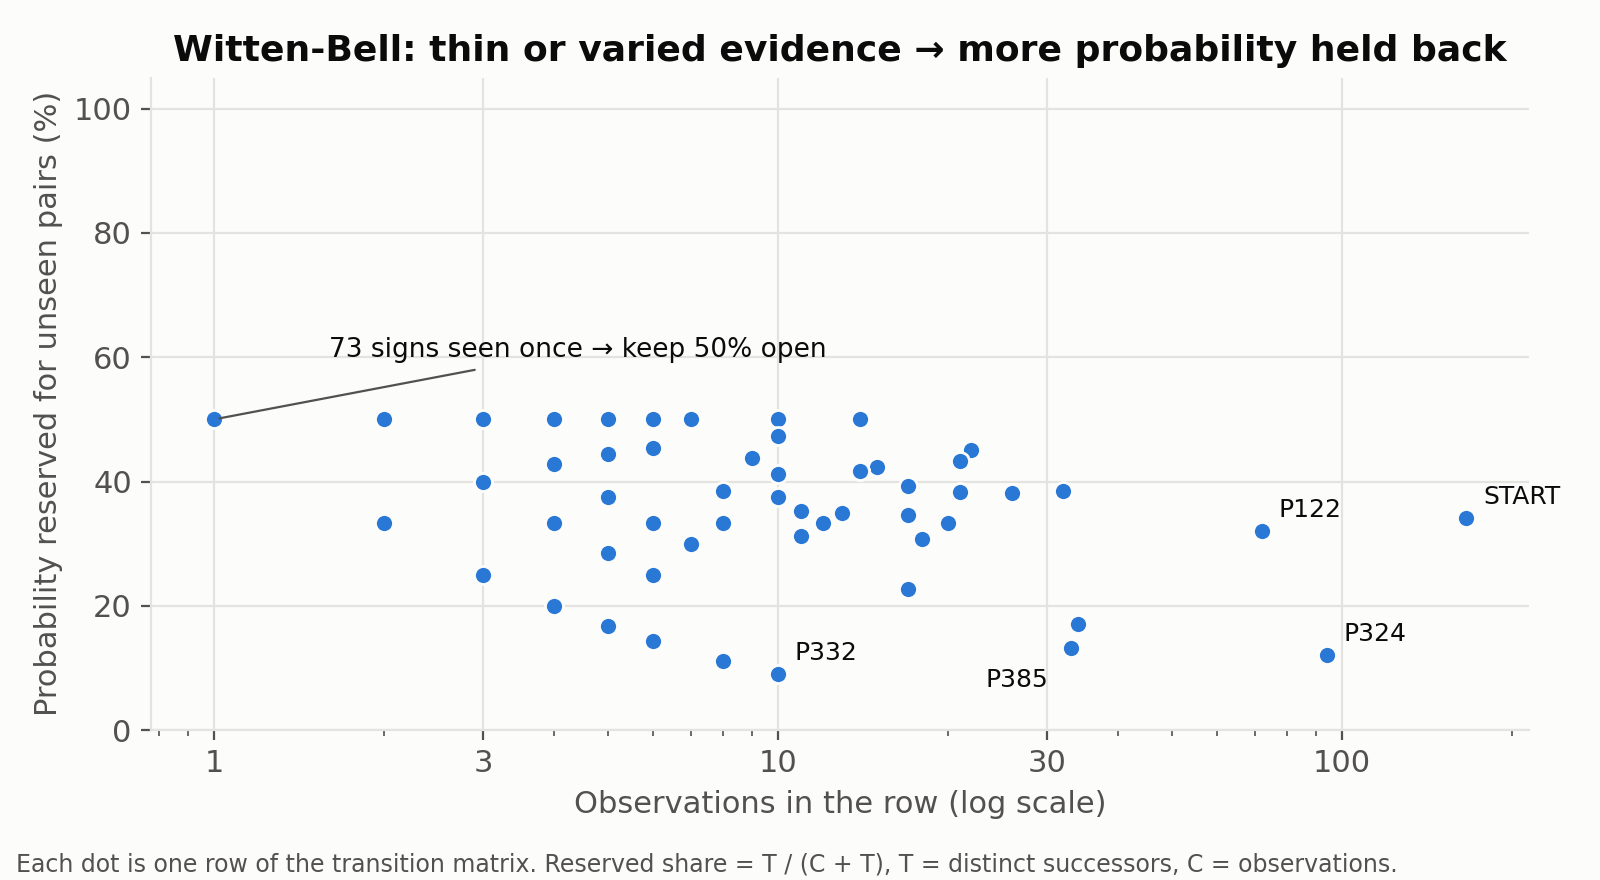

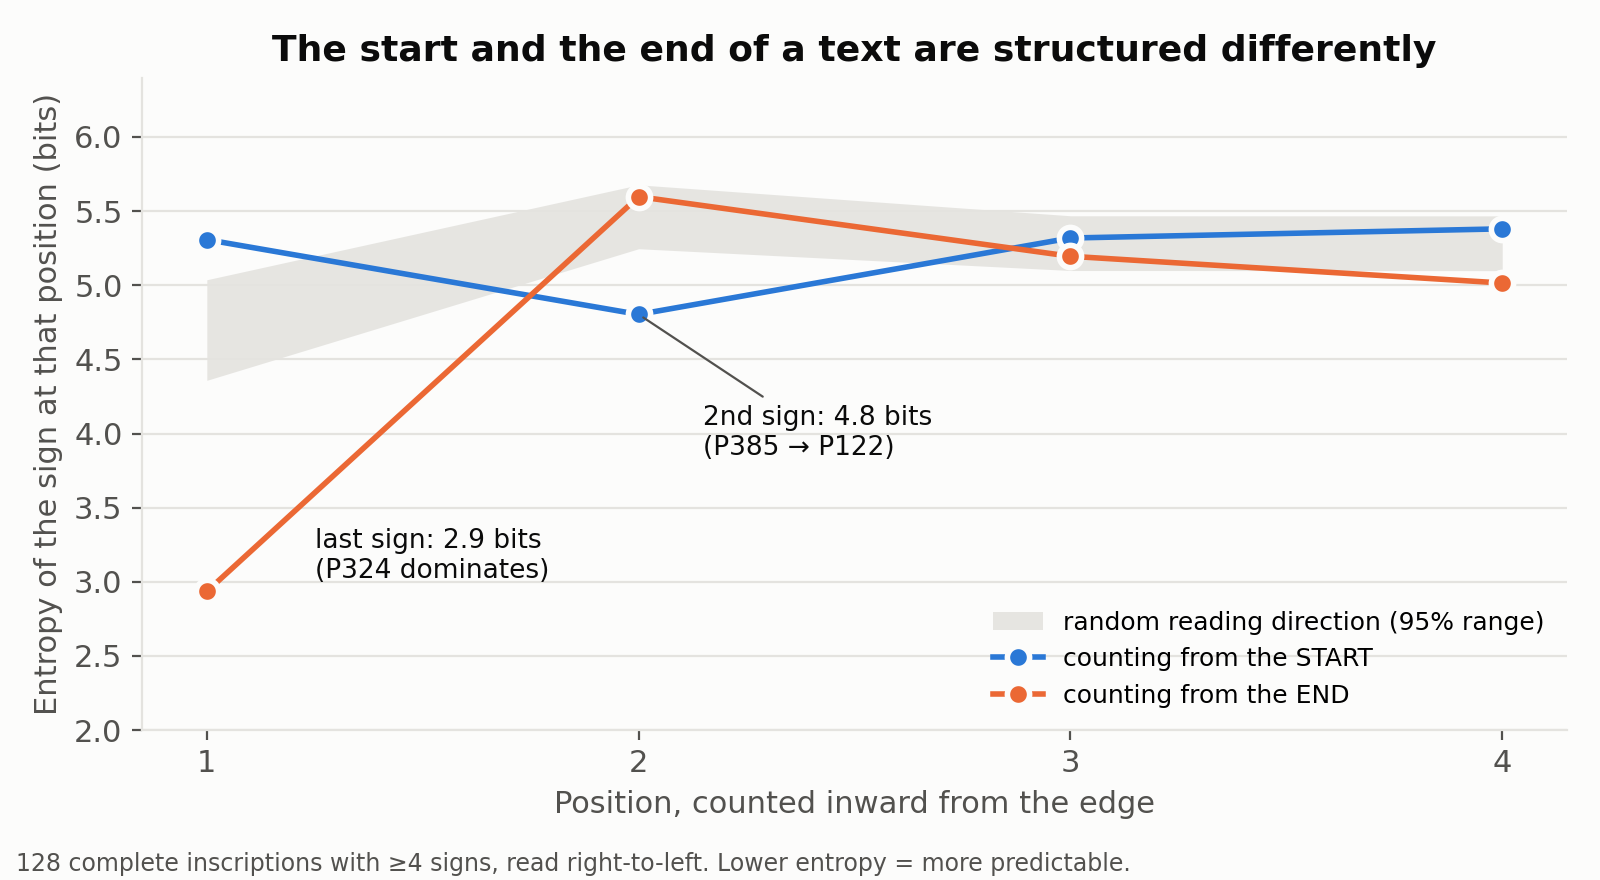

In [3]:
for f in ("m2_04_flip_test.png", "m2_06_witten_bell_reserve.png", "m2_07_positional_entropy.png"):
    display(Image(filename=str(ROOT / "src/m2_markov/outputs/figures" / f), width=760))

## 2. Cross-validation of the smoothing (10-fold, by inscription): from the M2 notebook
Plain MLE gives probability 0 to 46% of held-out pairs; Witten–Bell gives the lowest held-out perplexity.

In [4]:
display(pd.DataFrame(m2["step4_smoothing"]).T)

,zero_prob_events,perplexity
MLE (no smoothing),516,infinite (fails)
Add-one (Laplace),0.0,77.3
Witten-Bell,0.0,40.8


## 3. Replication on the Wells corpus (M3/M4 data, all sites)
The same definitions applied to both corpora. The CISI column must reproduce M2's numbers, which checks that the re-implementation is faithful.

In [5]:
r = json.load(open(ROOT / "reports/m2/replication_wells.json"))
keys = ["complete_texts", "top_ender_label", "top_ender_share", "top_beginner_label", "flip_test_jsd", "flip_test_null_max", "pos1_gap", "pos1_gap_null_max",
        "heldout_ppl_forward", "heldout_ppl_reversed", "folds_reading_order_better", "significant_collocations"]
display(pd.DataFrame({c: [r[c][k] for k in keys] for c in r}, index=keys))

,cisi_reproduction,wells_unique,wells_all_rows
complete_texts,153,2106,3312
top_ender_label,P324 (= Wells 740),W740 (= IM77 342),W740 (= IM77 342)
top_ender_share,0.453416,0.309659,0.272489
top_beginner_label,P385 (= Wells 817/861),W820 (= IM77 391),W032 (= IM77 87)
flip_test_jsd,0.890655,0.63314,0.633341
flip_test_null_max,0.418195,0.127506,0.079204
pos1_gap,2.372374,2.15415,2.300295
pos1_gap_null_max,1.306939,0.426189,0.398856
heldout_ppl_forward,40.643991,40.490649,26.471341
heldout_ppl_reversed,40.483586,41.844576,27.414413


## 4. External check: Mahadevan (1977), Table I

In [6]:
t = json.load(open(ROOT / "reports/m2/mahadevan_table1_check.json"))
print(f"rows recovered from OCR: {t['rows_recovered']}/417, tokens {t['tokens_recovered']}/{t['tokens_published']}")
display(pd.DataFrame({"Mahadevan": t["jar_sign_IM77_342"]["mahadevan_shares"], "our corpus": t["jar_sign_IM77_342"]["our_shares"]}).T)  # jar sign (IM77 342), share of positions, reading order
display(pd.DataFrame({"Mahadevan": t["mahadevan_aggregate_position_shares"], "our corpus": t["our_corpus_aggregate_position_shares"]}).T)

rows recovered from OCR: 307/417, tokens 9280/13372


,solo,initial,medial,final
Mahadevan,0.002,0.001,0.301,0.696
our corpus,0.008,0.004,0.303,0.684


,solo,initial,medial,final
Mahadevan,0.014,0.217,0.523,0.246
our corpus,0.027,0.242,0.489,0.242


## 5. Sign embeddings: word2vec vs LLM2Vec vs the M3 encoder (3 runs each)

In [7]:
display(Markdown((ROOT / "reports/m2/embedding_comparison.md").read_text().split("**How to read")[0]))

# Sign embeddings and gap filling: word2vec vs LLM2Vec vs our encoder

All models trained on the same Indus inscriptions (Milestone 3 v2 train split, 2,792 inscriptions, Wells numbering) and tested on the same 350 unseen test inscriptions. Values are the mean over 3 training runs, with the range in brackets (count-based and frequency baselines are deterministic, so they have one value).

| Method | Gap filling: first guess right | Gap filling: right sign in top 5 | Gap filling: perplexity (lower = better) | Knows a sign's position (random ≈ 0.32) | Recognises variants of the same sign (max 1.0) |
|---|---|---|---|---|---|
| Random vectors (control) | — | — | — | 0.32 (0.29–0.37) | 0.04 (0.02–0.05) |
| Unigram: always guess by frequency | 11.0% | 24.4% | 112 | — | — |
| Count-based embedding (PPMI-SVD) | — | — | — | 0.36 | 0.30 |
| **Word2vec** (skip-gram, negative sampling) | 22.0% (21.3%–22.5%) | 44.5% (44.0%–44.8%) | 186 (182–190) | 0.46 (0.42–0.52) | 0.52 (0.49–0.55) |
| LLM2Vec step 0: left-to-right model only | 24.6% (23.9%–24.9%) | 43.1% (42.7%–43.6%) | 53 (53–54) | 0.55 (0.52–0.61) | 0.60 (0.52–0.70) |
| LLM2Vec steps 1–2: + bidirectional + MNTP | 29.2% (27.8%–30.1%) | 50.2% (49.4%–51.5%) | 38 (36–39) | 0.60 (0.54–0.68) | 0.67 (0.59–0.74) |
| **LLM2Vec, full** (+ SimCSE) | 27.6% (26.3%–29.1%) | 47.2% (46.4%–48.5%) | 45 (42–47) | 0.59 (0.54–0.67) | 0.67 (0.59–0.74) |
| **M3 masked encoder** (single model; ± = std over 3 runs) | 32.7% (±0.5) | 54.9% (±0.6) | 32 (±0.2) | 0.62 (0.58–0.65) | 0.68 (0.62–0.75) |
| Witten–Bell bigram (Milestone 2) | 33.5% | 56.3% | 31 | — | — |
| M3 ensemble of 3 + calibration (deliverable) | 33.4% | 57.0% | 26 | — | — |

Contextual vectors (each sign encoded on its own between start and end markers) instead of the embedding table:

| Method | Knows a sign's position | Recognises variants |
|---|---|---|
| LLM2Vec, full: contextual vectors | 0.45 (0.43–0.47) | 0.59 (0.48–0.65) |
| M3 encoder: contextual vectors | 0.45 (0.44–0.46) | 0.52 (0.44–0.59) |

